# Défis liés aux données

Analyse exploratoire simple de quatre défis, pour les deux sources (NHL depuis MySQL,
MoneyPuck depuis les CSV) et pour les matchs, équipes, patineurs et gardiens :

1. **Disponibilité et qualité des données historiques** : couverture par saison, concordance
   entre les sources ;
2. **Disponibilité réelle de l'information avant les matchs** : fuite d'information,
   démarrage à froid en début de saison, calendrier ;
3. **Changements d'alignement et échanges de joueurs** : continuité d'un match à l'autre,
   gardien partant, joueurs ayant porté plusieurs uniformes, roulement entre saisons ;
4. **Déséquilibre entre le nombre de variables et le nombre d'observations**.

Saison régulière seulement, saisons terminées seulement (la saison en cours est exclue) ; la
saison est notée par son année de début (`2005` = 2005-2006).
Les figures et tableaux sont produits dans les cellules ; avec `SAUVER = True`, les figures
sont aussi enregistrées en PNG (300 dpi) dans `reports/map6009/figures/`.

In [22]:
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import roc_auc_score
from sqlalchemy import text

from nhl_forecast.config import PROJECT_ROOT, get_settings
from nhl_forecast.data.db.mysql import make_engine
from nhl_forecast.data.nhl_collect import stats_table
from nhl_forecast.data.sources.nhl_api import REPORTS
from nhl_forecast.visualization.style import appliquer_style, hachurer

In [23]:
SAUVER = True  # True : enregistre aussi les figures en PNG pour le rapport
FIG_DIR = PROJECT_ROOT / "reports" / "map6009" / "figures"

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.3f}".format)

BLEU, ORANGE, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
appliquer_style()  # couleurs + traits/marqueurs/hachures : lisible en noir et blanc

engine = make_engine()
DB = get_settings().mysql_database
MP_DIR = PROJECT_ROOT / "data" / "raw" / "moneypuck"
FIRST_GAME_ID = 2005_00_0000


def sql(query, **params):
    with engine.connect() as conn:
        return pd.read_sql(text(query), conn, params=params)


def saison_de(gid):
    """Saison (année de début) déduite du gameId (ex. 2005020001 -> 2005)."""
    return pd.Series(gid).astype("int64").to_numpy() // 1_000_000


def sauver(fig, nom):
    if SAUVER:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{nom}.png", dpi=300, bbox_inches="tight", facecolor="white")


def axe_saisons(ax):
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))


def pct(x):
    return f"{x:.1%}"

## 0. Chargement

Une seule lecture par source ; les sections suivantes réutilisent ces tables.

In [24]:
games = sql(
    """
    SELECT game_id, date, home, away, score_home, score_away, end_game_type
    FROM games
    WHERE league = 'nhl' AND status = 'OFF' AND game_type = 'R'
      AND season_id REGEXP '^[0-9]{8}$' AND season_id >= '20052006'
    """
)
games["gameId"] = games["game_id"].astype("int64")
games["saison"] = saison_de(games["gameId"])
games["date"] = pd.to_datetime(games["date"])
games["home_win"] = (games["score_home"] > games["score_away"]).astype(int)
# saisons terminées : on écarte la saison en cours (quelques matchs seulement)
SAISONS = games.groupby("saison").size().loc[lambda n: n >= 600].index
games = games[games["saison"].isin(SAISONS)]

nhl_t = sql(
    """
    SELECT s.gameId, s.teamId, s.homeRoad, s.gameDate, s.goalsFor, s.goalsAgainst,
           s.shotsForPerGame AS shotsFor, r.hits, r.giveaways, r.takeaways, r.blockedShots
    FROM t_summary s
    LEFT JOIN t_realtime r ON r.gameId = s.gameId AND r.teamId = s.teamId
    WHERE s.gameId >= :first AND (s.gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_sk = sql(
    """
    SELECT s.gameId, s.playerId, s.teamAbbrev, s.positionCode, s.gameDate, t.timeOnIce
    FROM summary s LEFT JOIN timeonice t ON t.gameId = s.gameId AND t.playerId = s.playerId
    WHERE s.gameId >= :first AND (s.gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_gk = sql(
    """
    SELECT gameId, playerId, teamAbbrev, gameDate, gamesStarted, timeOnIce
    FROM g_summary WHERE gameId >= :first AND (gameId DIV 10000) % 100 = 2
    """,
    first=FIRST_GAME_ID,
)
nhl_t, nhl_sk, nhl_gk = (
    df.assign(saison=saison_de(df["gameId"]), gameDate=pd.to_datetime(df["gameDate"])).query(
        "saison in @SAISONS"
    )
    for df in (nhl_t, nhl_sk, nhl_gk)
)

mp_t = pd.read_csv(MP_DIR / "teams" / "all_teams.csv", engine="pyarrow")
mp_t = mp_t[mp_t["playoffGame"] == 0]
mp_g = pd.concat(
    [pd.read_csv(f, engine="pyarrow") for f in sorted((MP_DIR / "goalies").glob("*.csv"))],
    ignore_index=True,
)
SK_COLS = [
    "playerId",
    "gameId",
    "season",
    "gameDate",
    "playerTeam",
    "position",
    "situation",
    "icetime",
]
mp_s = pd.concat(
    [
        pd.read_csv(f, engine="pyarrow", usecols=SK_COLS)
        for f in sorted((MP_DIR / "skaters").glob("*.csv"))
    ],
    ignore_index=True,
)
mp_t_all, mp_g_all, mp_s_all = (
    df[(df["situation"] == "all") & df["season"].isin(SAISONS)].assign(
        gameDate=lambda d: pd.to_datetime(d["gameDate"].astype(str), format="%Y%m%d")
    )
    for df in (mp_t, mp_g, mp_s)
)

pd.DataFrame(
    {
        "lignes": [
            len(games),
            len(nhl_t),
            len(nhl_sk),
            len(nhl_gk),
            len(mp_t_all),
            len(mp_s_all),
            len(mp_g_all),
        ],
        "saisons": [
            f"{d['saison'].min()}-{d['saison'].max()}" for d in (games, nhl_t, nhl_sk, nhl_gk)
        ]
        + [f"{d['season'].min()}-{d['season'].max()}" for d in (mp_t_all, mp_s_all, mp_g_all)],
    },
    index=pd.MultiIndex.from_tuples(
        [
            ("NHL", "matchs"),
            ("NHL", "équipes"),
            ("NHL", "patineurs"),
            ("NHL", "gardiens"),
            ("MoneyPuck", "équipes"),
            ("MoneyPuck", "patineurs"),
            ("MoneyPuck", "gardiens"),
        ]
    ),
)

lignes    saisons
NHL       matchs      25302  2005-2025
          équipes     50604  2005-2025
          patineurs  910628  2005-2025
          gardiens    54374  2005-2025
MoneyPuck équipes     43216  2008-2025
          patineurs  777367  2008-2025
          gardiens    46308  2008-2025

## 1. Disponibilité et qualité des données historiques

### 1.1 Couverture par saison

Proportion des matchs de saison régulière de `games` présents dans chaque source, par saison.
Côté NHL, une ligne par rapport statistique ; côté MoneyPuck, une ligne par fichier.

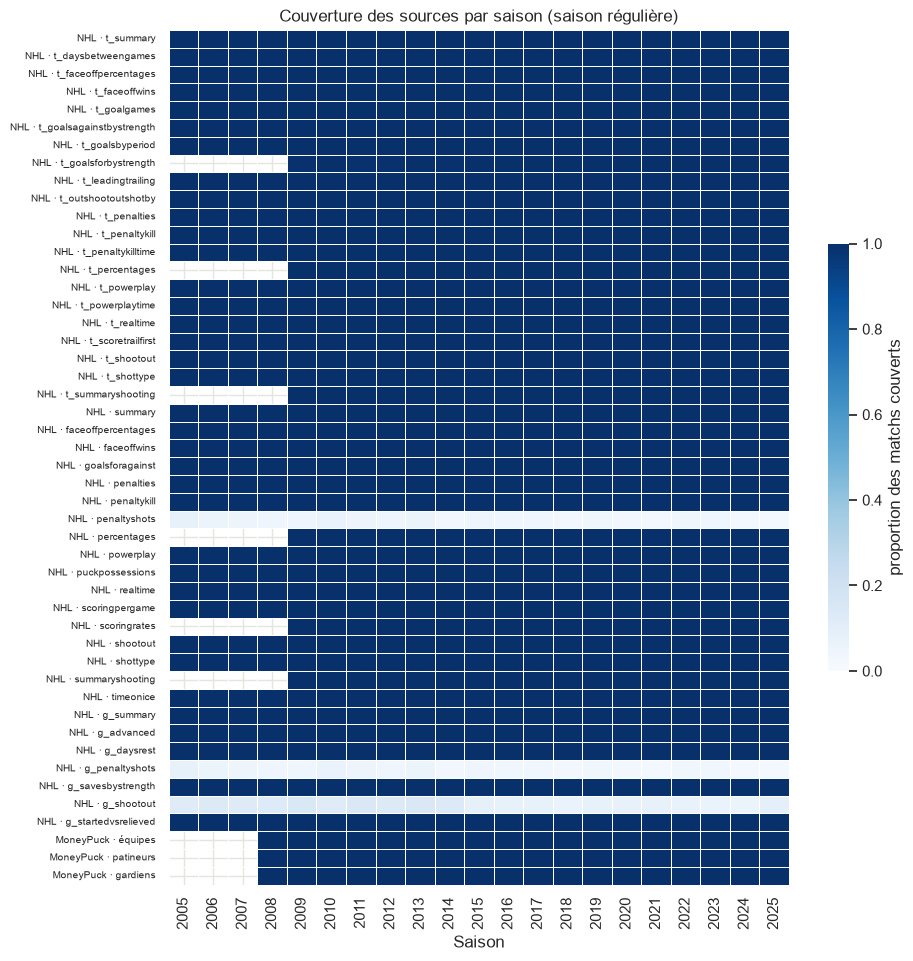

In [4]:
n_matchs = games.groupby("saison")["gameId"].nunique()

couv = {}
for entity, reports in REPORTS.items():
    for report in reports:
        table = stats_table(entity, report)
        df = sql(
            f"""
            SELECT gameId DIV 1000000 AS saison, COUNT(DISTINCT gameId) AS matchs
            FROM `{table}` WHERE gameId >= :first AND (gameId DIV 10000) % 100 = 2
            GROUP BY saison
            """,
            first=FIRST_GAME_ID,
        )
        couv[f"NHL · {table}"] = df.set_index("saison")["matchs"]
for nom, df in [("équipes", mp_t_all), ("patineurs", mp_s_all), ("gardiens", mp_g_all)]:
    couv[f"MoneyPuck · {nom}"] = df.groupby("season")["gameId"].nunique()

couverture = pd.DataFrame(couv).T.div(n_matchs, axis=1).clip(upper=1)
couverture = couverture.loc[:, couverture.columns <= n_matchs.index.max()]

fig, ax = plt.subplots(figsize=(10, 0.2 * len(couverture) + 1.5))
sns.heatmap(
    couverture,
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    cbar_kws={"label": "proportion des matchs couverts", "shrink": 0.5},
    ax=ax,
)
ax.set(xlabel="Saison", ylabel="", title="Couverture des sources par saison (saison régulière)")
ax.tick_params(axis="y", labelsize=7)
sauver(fig, "defis_couverture_sources")

In [5]:
# Première saison où chaque source couvre au moins 95 % des matchs
premiere = couverture.apply(lambda r: r[r >= 0.95].index.min(), axis=1)
premiere = premiere.astype("Int64").rename("première saison")
incomplets = (couverture < 0.95).sum(axis=1).rename("saisons < 95 %")
pd.concat([premiere, incomplets], axis=1).sort_values(
    ["première saison", "saisons < 95 %"], ascending=False
).head(15)

,première saison,saisons < 95 %
NHL · t_goalsforbystrength,2009,0
NHL · t_percentages,2009,0
NHL · t_summaryshooting,2009,0
NHL · percentages,2009,0
NHL · scoringrates,2009,0
NHL · summaryshooting,2009,0
MoneyPuck · équipes,2008,0
MoneyPuck · patineurs,2008,0
MoneyPuck · gardiens,2008,0
NHL · t_summary,2005,0


### 1.2 Concordance entre les sources

Les deux sources décrivent les mêmes matchs (MoneyPuck s'appuie sur les feuilles de match de
la NHL). On compare, pour chaque équipe-match présente dans les deux, quelques comptes
communs : une concordance faible signale une définition différente ou un problème de qualité.
Les buts sont comparés hors fusillade (MoneyPuck n'inclut pas le but de fusillade).

In [6]:
COMPARAISON = {  # NHL -> MoneyPuck
    "goalsFor": "goalsFor",
    "shotsFor": "shotsOnGoalFor",
    "hits": "hitsFor",
    "blockedShots": "blockedShotAttemptsAgainst",
    "giveaways": "giveawaysFor",
    "takeaways": "takeawaysFor",
}
mp_cmp = mp_t_all.assign(homeRoad=mp_t_all["home_or_away"].map({"HOME": "H", "AWAY": "R"}))
cmp = nhl_t.merge(
    mp_cmp[["gameId", "homeRoad", *COMPARAISON.values()]],
    on=["gameId", "homeRoad"],
    suffixes=("_nhl", "_mp"),
)
cmp = cmp.merge(games[["gameId", "end_game_type"]], on="gameId")

lignes = []
for v_nhl, v_mp in COMPARAISON.items():
    d = cmp if v_nhl != "goalsFor" else cmp[cmp["end_game_type"] != "SO"]
    a = d[f"{v_nhl}_nhl" if v_nhl == v_mp else v_nhl]
    b = d[f"{v_mp}_mp" if v_nhl == v_mp else v_mp]
    lignes.append(
        {
            "variable NHL": v_nhl,
            "variable MoneyPuck": v_mp,
            "équipes-matchs": len(d),
            "identiques": (a == b).mean(),
            "écart absolu moyen": (a - b).abs().mean(),
            "corrélation": a.corr(b),
        }
    )
concordance = pd.DataFrame(lignes).set_index("variable NHL")
concordance.style.format(
    {
        "identiques": "{:.1%}",
        "écart absolu moyen": "{:.2f}",
        "corrélation": "{:.3f}",
        "équipes-matchs": "{:,}",
    }
)

,variable MoneyPuck,équipes-matchs,identiques,écart absolu moyen,corrélation
variable NHL,,,,,
goalsFor,goalsFor,"38,938",99.7%,0.01,0.997
shotsFor,shotsOnGoalFor,"43,216",98.7%,0.03,0.997
hits,hitsFor,"43,216",99.4%,0.03,0.997
blockedShots,blockedShotAttemptsAgainst,"43,216",86.2%,0.27,0.986
giveaways,giveawaysFor,"43,216",64.6%,0.48,0.989
takeaways,takeawaysFor,"43,216",98.7%,0.02,0.998


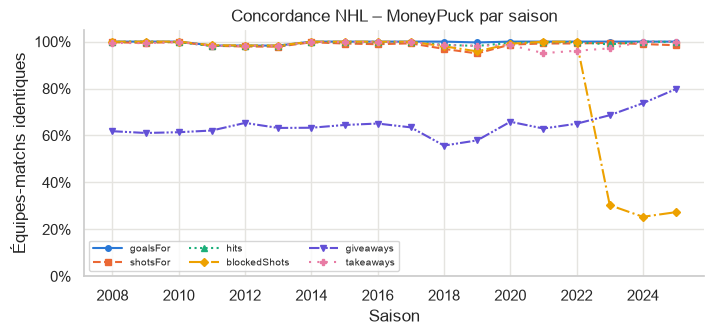

In [7]:
# Évolution de la concordance par saison
par_saison = {}
for v_nhl, v_mp in COMPARAISON.items():
    d = cmp if v_nhl != "goalsFor" else cmp[cmp["end_game_type"] != "SO"]
    a = d[f"{v_nhl}_nhl" if v_nhl == v_mp else v_nhl]
    b = d[f"{v_mp}_mp" if v_nhl == v_mp else v_mp]
    par_saison[v_nhl] = (a == b).groupby(d["saison"]).mean()
par_saison = pd.DataFrame(par_saison)

fig, ax = plt.subplots()
par_saison.plot(ax=ax)  # une couleur, un trait et un marqueur par variable
ax.set(
    xlabel="Saison",
    ylabel="Équipes-matchs identiques",
    ylim=(0, 1.05),
    title="Concordance NHL – MoneyPuck par saison",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(ncols=3, fontsize=7, loc="lower left")
axe_saisons(ax)
sauver(fig, "defis_concordance_sources")

## 2. Disponibilité réelle de l'information avant les matchs

### 2.1 Moment où chaque type d'information est connu

| Information | Exemple | Connue |
|---|---|---|
| Calendrier | domicile/extérieur, jours de repos, match la veille | des semaines avant |
| Historique des équipes et joueurs | moyennes mobiles, Elo, momentum | après le match précédent |
| Alignement | joueurs habillés, blessés, rappels | quelques heures avant, parfois au réchauffement |
| Gardien partant | annonce de l'entraîneur | le matin du match ou à la période d'échauffement |
| Statistiques du match | tirs, xG, temps de glace | seulement **après** le match |

Toutes les statistiques des sources sont des statistiques **du match** : pour prédire, il faut
les remplacer par des agrégats des matchs **précédents**. Ci-dessous, la capacité à séparer
victoires et défaites (AUC) d'une même variable selon qu'elle est mesurée pendant le match
(fuite d'information) ou avant (moyenne des 10 matchs précédents de la saison).

In [8]:
def avant_match(df, equipe, date, valeur, saison, fenetre=10):
    """Moyenne de `valeur` sur les `fenetre` matchs précédents de l'équipe dans la saison."""
    df = df.sort_values(date)
    g = df.groupby([saison, equipe])[valeur]
    return g.transform(lambda s: s.shift(1).rolling(fenetre, min_periods=1).mean())


# NHL : écart de buts ; MoneyPuck : part des buts attendus (xG %)
nhl_t["ecart"] = nhl_t["goalsFor"] - nhl_t["goalsAgainst"]
nhl_t["ecart_avant"] = avant_match(nhl_t, "teamId", "gameDate", "ecart", "saison")
mp_t_all["xg_avant"] = avant_match(mp_t_all, "playerTeam", "gameDate", "xGoalsPercentage", "season")


def par_match(df, cols, cote, home_val):
    d = df[df[cote] == home_val][["gameId", *cols]]
    a = df[df[cote] != home_val][["gameId", *cols]]
    return d.merge(a, on="gameId", suffixes=("_dom", "_ext"))


m_nhl = par_match(nhl_t, ["ecart", "ecart_avant"], "homeRoad", "H").merge(
    games[["gameId", "home_win"]], on="gameId"
)
m_mp = par_match(mp_t_all, ["xGoalsPercentage", "xg_avant"], "home_or_away", "HOME").merge(
    games[["gameId", "home_win"]], on="gameId"
)


def auc(y, x):
    ok = x.notna()
    return roc_auc_score(y[ok], x[ok])


auc = pd.DataFrame(
    [
        ("NHL", "écart de buts", "pendant le match", auc(m_nhl["home_win"], m_nhl["ecart_dom"])),
        (
            "NHL",
            "écart de buts",
            "10 matchs précédents",
            auc(m_nhl["home_win"], m_nhl["ecart_avant_dom"] - m_nhl["ecart_avant_ext"]),
        ),
        (
            "MoneyPuck",
            "part des xG",
            "pendant le match",
            auc(m_mp["home_win"], m_mp["xGoalsPercentage_dom"]),
        ),
        (
            "MoneyPuck",
            "part des xG",
            "10 matchs précédents",
            auc(m_mp["home_win"], m_mp["xg_avant_dom"] - m_mp["xg_avant_ext"]),
        ),
    ],
    columns=["source", "variable", "mesurée", "AUC"],
).set_index(["source", "variable", "mesurée"])
auc

AUC
source    variable      mesurée                   
NHL       écart de buts pendant le match     0.995
                        10 matchs précédents 0.561
MoneyPuck part des xG   pendant le match     0.691
                        10 matchs précédents 0.577

L'écart de buts du match détermine presque le résultat (AUC ≈ 1 ; seuls les matchs décidés en
fusillade, à écart nul, ne sont pas séparés) : c'est le cas extrême de fuite d'information. Mesurées avant le match, les mêmes variables ne séparent plus que faiblement
les victoires des défaites : c'est le niveau de signal réellement disponible.

### 2.2 Démarrage à froid en début de saison

Nombre de matchs déjà joués par chaque équipe dans la saison au moment du match. En début de
saison, les agrégats « avant le match » reposent sur très peu d'observations (ou doivent
reprendre la saison précédente).

In [9]:
long = pd.concat(
    [
        games[["gameId", "saison", "date", "home"]].rename(columns={"home": "team"}),
        games[["gameId", "saison", "date", "away"]].rename(columns={"away": "team"}),
    ],
    ignore_index=True,
).sort_values("date")
long["joues_avant"] = long.groupby(["saison", "team"]).cumcount()
long["repos"] = long.groupby(["saison", "team"])["date"].diff().dt.days - 1
min_joues = long.groupby("gameId")["joues_avant"].min()

froid = pd.DataFrame(
    {f"< {k} matchs": [(min_joues < k).mean()] for k in (1, 5, 10, 20)},
    index=["matchs où au moins une équipe a joué"],
)
froid.style.format("{:.1%}")

,< 1 matchs,< 5 matchs,< 10 matchs,< 20 matchs
matchs où au moins une équipe a joué,1.5%,6.8%,13.4%,26.3%


### 2.3 Calendrier : jours de repos

Information connue longtemps à l'avance. Répartition des jours de repos avant un match et
taux de victoire selon la situation de repos.

In [10]:
rep = long.dropna(subset=["repos"]).copy()
rep["repos_cat"] = pd.cut(
    rep["repos"], [-1, 0, 1, 2, 365], labels=["0 (veille)", "1", "2", "3 et +"]
)
g = games.merge(
    rep[["gameId", "team", "repos_cat"]], left_on=["gameId", "home"], right_on=["gameId", "team"]
).merge(
    rep[["gameId", "team", "repos_cat"]],
    left_on=["gameId", "away"],
    right_on=["gameId", "team"],
    suffixes=("_dom", "_ext"),
)
tab_repos = pd.crosstab(
    g["repos_cat_dom"], g["repos_cat_ext"], values=g["home_win"], aggfunc="mean"
)
print("Répartition des jours de repos (équipe-match) :")
display(rep["repos_cat"].value_counts(normalize=True).sort_index().to_frame("part"))
print("Taux de victoire locale selon le repos (lignes : local, colonnes : visiteur) :")
tab_repos.style.format("{:.1%}").background_gradient(cmap="RdBu", vmin=0.45, vmax=0.65)

Répartition des jours de repos (équipe-match) :


,part
repos_cat,
0 (veille),0.173
1,0.556
2,0.189
3 et +,0.082


Taux de victoire locale selon le repos (lignes : local, colonnes : visiteur) :


repos_cat_ext,0 (veille),1,2,3 et +
repos_cat_dom,,,,
0 (veille),53.8%,49.9%,46.7%,41.6%
1,59.5%,54.2%,52.1%,56.2%
2,59.4%,55.2%,53.5%,56.2%
3 et +,54.5%,53.1%,49.7%,51.3%


## 3. Changements d'alignement et échanges de joueurs

### 3.1 Continuité de l'alignement d'un match à l'autre

Pour chaque équipe-match, nombre de patineurs absents du match précédent de l'équipe (même
saison). Un modèle qui agrège les joueurs doit suivre ces changements ; un modèle au niveau de
l'équipe les ignore.

au moins un changement : {'NHL': '68.8%', 'MoneyPuck': '69.0%'}


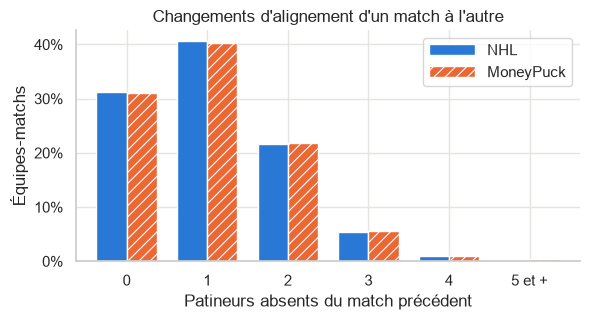

In [11]:
def changements(df, equipe, date, saison, joueur):
    lineups = (
        df.groupby([saison, equipe, "gameId", date])[joueur]
        .agg(frozenset)
        .reset_index()
        .sort_values(date)
    )
    prec = lineups.groupby([saison, equipe])[joueur].shift(1)
    ok = prec.notna()
    lineups = lineups[ok].copy()
    lineups["nouveaux"] = [len(a - b) for a, b in zip(lineups[joueur], prec[ok], strict=True)]
    return lineups


ch_nhl = changements(nhl_sk, "teamAbbrev", "gameDate", "saison", "playerId")
ch_mp = changements(mp_s_all, "playerTeam", "gameDate", "season", "playerId")

dist = (
    pd.DataFrame(
        {
            "NHL": ch_nhl["nouveaux"].clip(upper=5).value_counts(normalize=True),
            "MoneyPuck": ch_mp["nouveaux"].clip(upper=5).value_counts(normalize=True),
        }
    )
    .sort_index()
    .rename(index={5: "5 et +"})
)

fig, ax = plt.subplots(figsize=(6.5, 3))
dist.plot.bar(ax=ax, width=0.75, color=[BLEU, ORANGE], edgecolor="white", rot=0)
hachurer(ax)
ax.legend()
ax.set(
    xlabel="Patineurs absents du match précédent",
    ylabel="Équipes-matchs",
    title="Changements d'alignement d'un match à l'autre",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
sauver(fig, "defis_changements_alignement")
print(
    "au moins un changement :",
    {"NHL": pct((ch_nhl["nouveaux"] > 0).mean()), "MoneyPuck": pct((ch_mp["nouveaux"] > 0).mean())},
)

### 3.2 Gardien partant

Le gardien partant change-t-il d'un match à l'autre ? Côté NHL, il est indiqué
(`gamesStarted`) ; côté MoneyPuck, on le déduit (plus long temps de glace). Le taux de
changement dépend fortement du calendrier (match la veille).

In [12]:
def partant_change(df, equipe, date, saison, est_partant):
    # partant de chaque équipe-match, comparé à celui du match précédent de l'équipe
    p = df[est_partant].sort_values(date).copy()
    g = p.groupby([saison, equipe])
    p["precedent"] = g["playerId"].shift(1)
    p["repos"] = g[date].diff().dt.days - 1
    p = p.dropna(subset=["precedent"])
    p["change"] = p["playerId"] != p["precedent"]
    p["veille"] = np.where(p["repos"] == 0, "match la veille", "au moins 1 jour de repos")
    return p.rename(columns={saison: "saison"})


p_nhl = partant_change(nhl_gk, "teamAbbrev", "gameDate", "saison", nhl_gk["gamesStarted"] == 1)
rang = mp_g_all.groupby(["gameId", "playerTeam"])["icetime"].rank(ascending=False, method="first")
p_mp = partant_change(mp_g_all, "playerTeam", "gameDate", "season", rang == 1)

tab_gardien = pd.DataFrame(
    {
        "NHL": p_nhl.groupby("veille")["change"].mean(),
        "MoneyPuck": p_mp.groupby("veille")["change"].mean(),
    }
)
tab_gardien.loc["ensemble"] = [p_nhl["change"].mean(), p_mp["change"].mean()]
tab_gardien.style.format("{:.1%}")

,NHL,MoneyPuck
veille,,
au moins 1 jour de repos,39.8%,41.6%
match la veille,71.3%,73.0%
ensemble,45.2%,47.0%


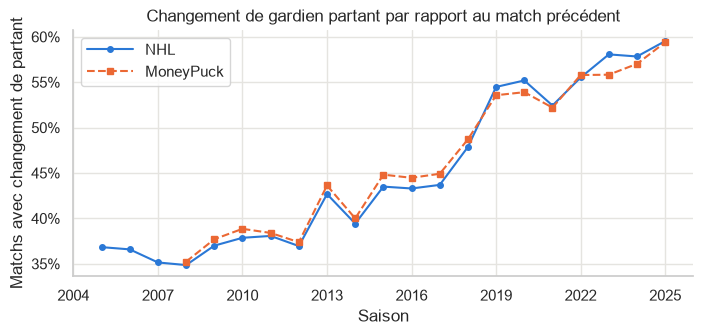

In [13]:
fig, ax = plt.subplots()
for p, nom in [(p_nhl, "NHL"), (p_mp, "MoneyPuck")]:
    s = p.groupby("saison")["change"].mean()
    ax.plot(s.index, s.values, label=nom)  # trait et marqueur distincts (cycle de style)
ax.set(
    xlabel="Saison",
    ylabel="Matchs avec changement de partant",
    title="Changement de gardien partant par rapport au match précédent",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend()
axe_saisons(ax)
sauver(fig, "defis_changement_gardien")

### 3.3 Joueurs ayant joué pour plusieurs équipes dans une saison

Échanges, réclamations au ballottage et signatures en cours de saison : un même joueur
contribue alors aux statistiques de plusieurs équipes.

,NHL patineurs,NHL gardiens,MoneyPuck patineurs,MoneyPuck gardiens
2018,81,7,81,7
2019,65,5,65,5
2020,58,3,58,3
2021,78,6,78,6
2022,95,4,95,4
2023,69,3,69,3
2024,102,9,102,9
2025,81,2,81,2


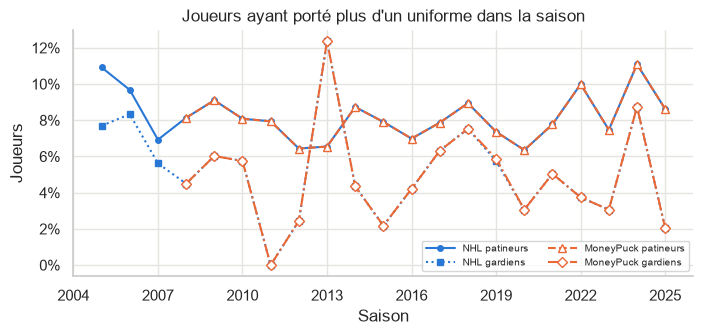

In [14]:
def multi_equipes(df, saison, equipe):
    n = df.groupby([saison, "playerId"])[equipe].nunique()
    return (n > 1).groupby(level=0).agg(["sum", "mean"])


me = pd.concat(
    {
        "NHL patineurs": multi_equipes(nhl_sk, "saison", "teamAbbrev"),
        "NHL gardiens": multi_equipes(nhl_gk, "saison", "teamAbbrev"),
        "MoneyPuck patineurs": multi_equipes(mp_s_all, "season", "playerTeam"),
        "MoneyPuck gardiens": multi_equipes(mp_g_all, "season", "playerTeam"),
    },
    axis=1,
)
fig, ax = plt.subplots()
# couleur = source ; trait et marqueur = source x type de joueur (lisible en N&B).
# Les courbes NHL et MoneyPuck se superposent : marqueurs MoneyPuck vides pour voir les deux.
STYLE = {
    "NHL patineurs": {"color": BLEU, "ls": "-", "marker": "o"},
    "NHL gardiens": {"color": BLEU, "ls": ":", "marker": "s"},
    "MoneyPuck patineurs": {"color": ORANGE, "ls": "--", "marker": "^", "mfc": "white", "ms": 6},
    "MoneyPuck gardiens": {"color": ORANGE, "ls": "-.", "marker": "D", "mfc": "white", "ms": 5},
}
for nom, style in STYLE.items():
    ax.plot(me.index, me[(nom, "mean")], label=nom, **style)
ax.set(
    xlabel="Saison", ylabel="Joueurs", title="Joueurs ayant porté plus d'un uniforme dans la saison"
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(fontsize=7, ncols=2)
axe_saisons(ax)
sauver(fig, "defis_joueurs_multi_equipes")
me.xs("sum", axis=1, level=1).astype("Int64").tail(8)

### 3.4 Roulement des effectifs entre deux saisons

Part du temps de glace des patineurs d'une équipe fournie par des joueurs qui avaient déjà
joué pour cette équipe la saison précédente. Les déménagements de franchise sont regroupés
(ATL → WPG en 2011 ; PHX → ARI en 2014 ; ARI → UTA en 2024).

saison,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
min,0.431,0.583,0.388,0.507,0.549,0.417,0.605,0.630,0.635,0.524,0.480,0.555,0.629,0.628,0.460,0.425,0.599,0.521,0.467,0.630
50%,0.735,0.767,0.742,0.773,0.766,0.756,0.767,0.790,0.769,0.768,0.798,0.808,0.796,0.777,0.750,0.738,0.800,0.797,0.752,0.783
max,0.914,0.948,0.939,0.909,0.900,0.893,0.930,0.938,0.972,0.971,0.917,0.935,0.957,0.954,0.961,0.908,0.927,0.950,0.937,0.919


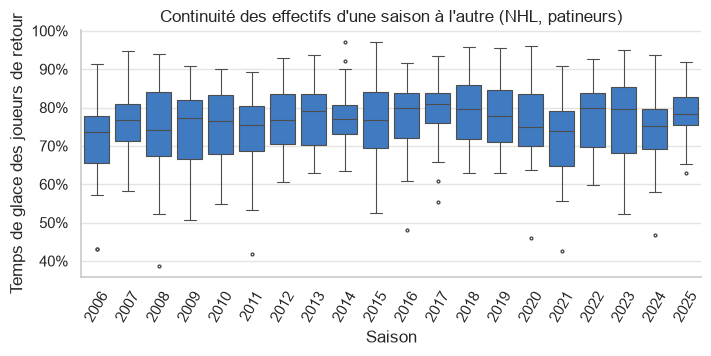

In [15]:
FRANCHISE = {"ATL": "WPG", "PHX": "UTA", "ARI": "UTA"}
sk = nhl_sk.assign(franchise=nhl_sk["teamAbbrev"].replace(FRANCHISE))
toi = sk.groupby(["saison", "franchise", "playerId"])["timeOnIce"].sum().reset_index()
deja = toi[["saison", "franchise", "playerId"]].assign(saison=lambda d: d["saison"] + 1)
toi = toi.merge(deja, on=["saison", "franchise", "playerId"], how="left", indicator=True)
toi["deja"] = toi["_merge"] == "both"
part = (
    toi.assign(tg_deja=toi["timeOnIce"] * toi["deja"])
    .groupby(["saison", "franchise"])[["tg_deja", "timeOnIce"]]
    .sum()
)
part = (part["tg_deja"] / part["timeOnIce"]).rename("part").reset_index()
# exclut la 1re saison de chaque franchise (2005, VGK 2017, SEA 2021) : pas de saison précédente
part = part[part.groupby("franchise")["saison"].transform("min") < part["saison"]]

fig, ax = plt.subplots()
sns.boxplot(part, x="saison", y="part", color=BLEU, fliersize=2, linewidth=0.8, ax=ax)
ax.set(
    xlabel="Saison",
    ylabel="Temps de glace des joueurs de retour",
    title="Continuité des effectifs d'une saison à l'autre (NHL, patineurs)",
)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.tick_params(axis="x", rotation=60)
sauver(fig, "defis_roulement_effectifs")
part.groupby("saison")["part"].describe()[["min", "50%", "max"]].T

## 4. Déséquilibre entre le nombre de variables et le nombre d'observations

Les sources offrent des centaines de statistiques par équipe et par joueur, mais une saison ne
compte que 1 230 à 1 312 matchs. Le nombre de variables d'un modèle (*p*) peut donc rapidement
s'approcher du nombre d'observations (*n*), voire le dépasser, surtout lorsqu'on décrit un match
par ses joueurs ou par plusieurs fenêtres temporelles.

### 4.1 Variables disponibles et observations

Variables numériques par entité (identifiants exclus). Côté NHL, une variable présente dans
plusieurs rapports n'est comptée qu'une fois ; côté MoneyPuck, chaque variable existe pour
cinq situations de jeu (`all`, `5on5`, `5on4`, `4on5`, `other`). Les colonnes « par
équipe-match » et « par match » multiplient par le nombre de joueurs d'une équipe dans un match
(18 patineurs habillés et 1 gardien partant, ce que confirment les données) et par les deux
équipes.

In [25]:
ID_COLS = {"gameId", "teamId", "playerId", "season", "gameDate", "gamesPlayed"}
NUMERIQUES = ("int", "bigint", "smallint", "tinyint", "float", "double", "decimal")
SITUATIONS = 5  # all, 5on5, 5on4, 4on5, other

colonnes = sql(
    "SELECT TABLE_NAME AS t, COLUMN_NAME AS c, DATA_TYPE AS d "
    "FROM information_schema.columns WHERE table_schema = :db",
    db=DB,
)
colonnes = colonnes[colonnes["d"].isin(NUMERIQUES) & ~colonnes["c"].isin(ID_COLS)]
n_vars = {}
for entity, nom in [("team", "équipes"), ("skater", "patineurs"), ("goalie", "gardiens")]:
    tables = [stats_table(entity, r) for r in REPORTS[entity]]
    n_vars[("NHL", nom)] = colonnes.loc[colonnes["t"].isin(tables), "c"].nunique()

mp_cols = {}
for nom, f in {"équipes": "teams/all_teams.csv", "patineurs": "skaters/2025.csv",
               "gardiens": "goalies/2025.csv"}.items():
    d = pd.read_csv(MP_DIR / f, nrows=500)
    mp_cols[nom] = [c for c in d.select_dtypes("number").columns if c not in ID_COLS]
    n_vars[("MoneyPuck", nom)] = len(mp_cols[nom]) * SITUATIONS

# joueurs par équipe-match : 18 patineurs habillés et 1 gardien partant (règle de la LNH) ;
# les moyennes observées (17,997 et 1,0) sont arrondies pour garder des comptes entiers
habilles = {
    "équipes": 1,
    "patineurs": round(nhl_sk.groupby(["gameId", "teamAbbrev"]).size().mean()),
    "gardiens": round(nhl_gk.groupby(["gameId", "teamAbbrev"])["gamesStarted"].sum().mean()),
}
tab_vars = pd.Series(n_vars, name="variables").rename_axis(["source", "entité"]).to_frame()
tab_vars["joueurs par équipe-match"] = [habilles[e] for _, e in tab_vars.index]
tab_vars["par équipe-match"] = tab_vars["variables"] * tab_vars["joueurs par équipe-match"]
tab_vars["par match (2 équipes)"] = 2 * tab_vars["par équipe-match"]
tab_vars.style.format("{:,.0f}")

In [26]:
n_saison = games.groupby("saison").size()
tab_obs = pd.Series(
    {
        "1 saison (médiane)": n_saison.median(),
        "1 saison (minimum, saison écourtée)": n_saison.min(),
        "5 saisons": n_saison.sort_index().tail(5).sum(),
        "MoneyPuck 2008-2025": n_saison.loc[2008:].sum(),
        "NHL 2005-2025": n_saison.sum(),
        "matchs d'une équipe dans une saison": 82,
    },
    name="observations (matchs)",
).to_frame()
tab_obs.style.format("{:,.0f}")

,observations (matchs)
1 saison (médiane),"1,230"
"1 saison (minimum, saison écourtée)",720
5 saisons,"6,560"
MoneyPuck 2008-2025,"21,612"
NHL 2005-2025,"25,302"
matchs d'une équipe dans une saison,82


### 4.2 Nombre de variables selon la représentation d'un match

Le nombre de variables dépend surtout de la façon de représenter un match. Chaque
représentation ci-dessous multiplie une plus simple : deux équipes, plusieurs situations de
jeu, plusieurs fenêtres temporelles (p. ex. 5 et 10 derniers matchs et saison en cours), puis
le détail par joueur. Les lignes verticales donnent le nombre de matchs disponibles.

,variables (p),p / n (1 saison),p / n (5 saisons),p / n (2005-2025)
"Équipe, situation « all » (MoneyPuck)",202,0.16,0.03,0.01
"Équipe, 5 situations (MoneyPuck)","1,010",0.82,0.15,0.04
"Équipe, 21 rapports (NHL)",574,0.47,0.09,0.02
Équipe NHL × 3 fenêtres,"1,722",1.40,0.26,0.07
Joueurs NHL (patineurs + gardien),"8,696",7.07,1.33,0.34
Joueurs NHL × 3 fenêtres,"26,088",21.21,3.98,1.03


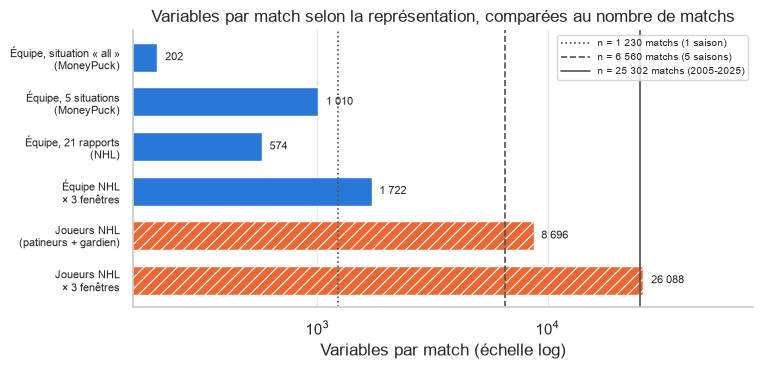

In [27]:
FENETRES = 3  # p. ex. 5 derniers matchs, 10 derniers matchs, saison en cours
p_joueurs = sum(habilles[e] * n_vars[("NHL", e)] for e in ("patineurs", "gardiens"))
representations = pd.Series(
    {
        "Équipe, situation « all »\n(MoneyPuck)": 2 * len(mp_cols["équipes"]),
        "Équipe, 5 situations\n(MoneyPuck)": 2 * n_vars[("MoneyPuck", "équipes")],
        "Équipe, 21 rapports\n(NHL)": 2 * n_vars[("NHL", "équipes")],
        "Équipe NHL\n× 3 fenêtres": 2 * n_vars[("NHL", "équipes")] * FENETRES,
        "Joueurs NHL\n(patineurs + gardien)": 2 * p_joueurs,
        "Joueurs NHL\n× 3 fenêtres": 2 * p_joueurs * FENETRES,
    }
).round()
REF_N = {  # nombres d'observations de référence, un trait différent pour chacun
    "1 saison": (n_saison.median(), ":"),
    "5 saisons": (n_saison.sort_index().tail(5).sum(), "--"),
    "2005-2025": (n_saison.sum(), "-"),
}


def milliers(v):
    return f"{v:,.0f}".replace(",", " ")


fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(representations))[::-1]
barres = ax.barh(y, representations.values, color=BLEU, edgecolor="white", height=0.65)
for b, (nom, v) in zip(barres, representations.items(), strict=True):
    if nom.startswith("Joueurs"):  # orange hachuré : représentation par joueur
        b.set_facecolor(ORANGE)
        b.set_hatch("///")
    ax.text(v * 1.08, b.get_y() + b.get_height() / 2, milliers(v), va="center", fontsize=8)
for nom, (n, ls) in REF_N.items():
    ax.axvline(n, color=GRIS, ls=ls, lw=1.2, marker="", label=f"n = {milliers(n)} matchs ({nom})")
ax.set_yticks(y, representations.index, fontsize=8)
ax.set_xscale("log")
ax.set_xlim(right=representations.max() * 3)
ax.set(
    xlabel="Variables par match (échelle log)",
    title="Variables par match selon la représentation, comparées au nombre de matchs",
)
ax.grid(axis="y", visible=False)
ax.legend(fontsize=7, loc="upper right")
sauver(fig, "defis_variables_vs_observations")

tab_pn = pd.DataFrame(
    {"variables (p)": representations.values}
    | {f"p / n ({nom})": representations.values / n for nom, (n, _) in REF_N.items()},
    index=representations.index.str.replace("\n", " "),
)
tab_pn.style.format("{:.2f}").format("{:,.0f}", subset=["variables (p)"])

### 4.3 Illustrations simples : stats des joueurs contre nombre de matchs

Cinq façons simples de montrer le même constat : décrire un match à partir des statistiques
de chaque joueur donne beaucoup plus de variables qu'une saison ne compte de matchs. Saison de
référence : la dernière saison complète ; joueurs : patineurs habillés et gardien partant
(18 patineurs et 1 gardien par équipe, section 4.1).

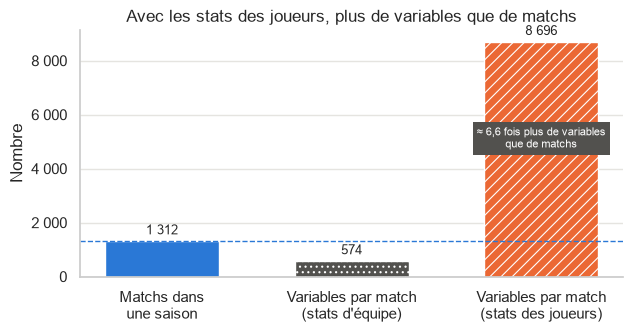

In [28]:
N_REF = n_saison.loc[SAISONS.max()]  # matchs de la dernière saison complète
P_EQ = 2 * n_vars[("NHL", "équipes")]
P_JR = 2 * p_joueurs
N_PAT = habilles["patineurs"]
V_PAT, V_GAR = n_vars[("NHL", "patineurs")], n_vars[("NHL", "gardiens")]


def virgule(v, d=1):
    return f"{v:.{d}f}".replace(".", ",")


# A. Trois barres, échelle linéaire
fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [N_REF, P_EQ, P_JR]
b = ax.bar(
    ["Matchs dans\nune saison", "Variables par match\n(stats d'équipe)",
     "Variables par match\n(stats des joueurs)"],
    vals, color=[BLEU, GRIS, ORANGE], edgecolor="white", hatch=["", "...", "///"], width=0.6,
)
ax.bar_label(b, labels=[milliers(v) for v in vals], padding=3)
ax.axhline(N_REF, color=BLEU, ls="--", lw=1, marker="")
ax.annotate(f"≈ {virgule(P_JR / N_REF)} fois plus de variables\nque de matchs",
            xy=(2, P_JR * 0.55), ha="center", fontsize=8, color="white",
            bbox={"fc": GRIS, "ec": "none", "pad": 3})
ax.set(ylabel="Nombre", title="Avec les stats des joueurs, plus de variables que de matchs")
ax.yaxis.set_major_formatter(lambda v, _: milliers(v))
ax.grid(axis="x", visible=False)
sauver(fig, "defis_simple_A_trois_barres")

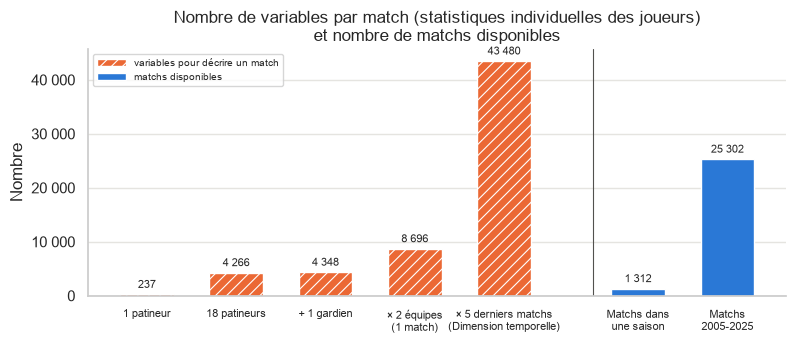

In [31]:
# B. Construction pas à pas du nombre de variables d'un match
DERNIERS = 5
etapes = [
    ("1 patineur", V_PAT),
    (f"{N_PAT} patineurs", N_PAT * V_PAT),
    ("+ 1 gardien", N_PAT * V_PAT + V_GAR),
    ("× 2 équipes\n(1 match)", P_JR),
    # aspect temporel : stats des joueurs sur chacun des 5 matchs précédents (séquence)
    (f"× {DERNIERS} derniers matchs\n(Dimension temporelle)", P_JR * DERNIERS),
]
matchs = [
    ("Matchs dans\nune saison", N_REF),
    (f"Matchs\n{SAISONS.min()}-{SAISONS.max()}", n_saison.sum()),
]
fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(len(etapes))
x_m = len(etapes) + 0.5 + np.arange(len(matchs))
b1 = ax.bar(x, [v for _, v in etapes], color=ORANGE, edgecolor="white", hatch="///",
            width=0.6, label="variables pour décrire un match")
b2 = ax.bar(x_m, [v for _, v in matchs], color=BLEU, edgecolor="white", width=0.6,
            label="matchs disponibles")
ax.bar_label(b1, labels=[milliers(v) for _, v in etapes], padding=3, fontsize=8)
ax.bar_label(b2, labels=[milliers(v) for _, v in matchs], padding=3, fontsize=8)
ax.axvline(len(etapes), color=GRIS, lw=0.8, marker="")
ax.set_xticks([*x, *x_m], [n for n, _ in etapes + matchs], fontsize=8)
ax.set(
    ylabel="Nombre",
    title="Nombre de variables par match (statistiques individuelles des joueurs)\n"
    "et nombre de matchs disponibles",
)
ax.yaxis.set_major_formatter(lambda v, _: milliers(v))
ax.grid(axis="x", visible=False)
ax.legend(fontsize=7, loc="upper left")
sauver(fig, "defis_simple_B_cascade")

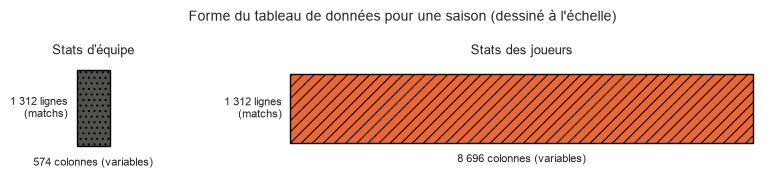

In [21]:
from matplotlib.transforms import blended_transform_factory

# C. Forme du tableau de données d'une saison, dessinée à l'échelle
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), gridspec_kw={"width_ratios": [1, 3.2]})
for ax, (titre, p, coul, hach) in zip(
    axes,
    [("Stats d'équipe", P_EQ, GRIS, "..."), ("Stats des joueurs", P_JR, ORANGE, "///")],
    strict=True,
):
    ax.add_patch(mpatches.Rectangle((0, 0), p, N_REF, fc=coul, ec="black", hatch=hach, lw=1))
    ax.set_xlim(-200, P_JR * 1.02 if p == P_JR else P_EQ * 4.2)
    ax.set_ylim(-250, N_REF * 1.05)
    ax.set_aspect("equal")
    ax.axis("off")
    # x en données, y en fraction de la figure : les deux titres restent alignés
    ax.text(p / 2, 0.66, titre, ha="center", va="bottom", fontsize=9,
            transform=blended_transform_factory(ax.transData, fig.transFigure))
    ax.annotate("", xy=(0, -120), xytext=(p, -120), arrowprops={"arrowstyle": "<->", "lw": 1})
    ax.text(p / 2, -200, f"{milliers(p)} colonnes (variables)", ha="center", va="top",
            fontsize=8)
    ax.annotate("", xy=(-100, 0), xytext=(-100, N_REF),
                arrowprops={"arrowstyle": "<->", "lw": 1})
    ax.text(-150, N_REF / 2, f"{milliers(N_REF)} lignes\n(matchs)", ha="right", va="center",
            fontsize=8)
fig.suptitle("Forme du tableau de données pour une saison (dessiné à l'échelle)", fontsize=10,
             y=0.8)
sauver(fig, "defis_simple_C_forme_tableau")

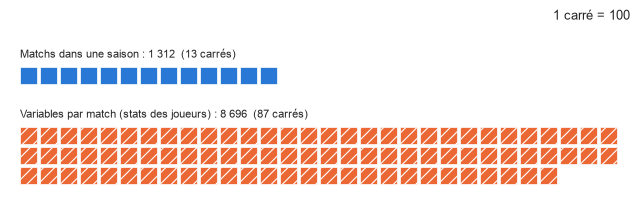

In [22]:
# D. Pictogramme : 1 carré = 100
PAR_LIGNE, UNITE = 30, 100
fig, ax = plt.subplots(figsize=(8, 3))
y0 = 0
for nom, v, coul, hach in [("Matchs dans une saison", N_REF, BLEU, ""),
                           ("Variables par match (stats des joueurs)", P_JR, ORANGE, "///")]:
    k = round(v / UNITE)
    for j in range(k):
        ax.add_patch(mpatches.Rectangle((j % PAR_LIGNE, y0 - j // PAR_LIGNE), 0.85, 0.85,
                                        fc=coul, ec="white", hatch=hach, lw=0.5))
    ax.text(0, y0 + 1.2, f"{nom} : {milliers(v)}  ({k} carrés)", fontsize=8, va="bottom")
    y0 -= (k - 1) // PAR_LIGNE + 3
ax.set_xlim(-0.5, PAR_LIGNE + 0.5)
ax.set_ylim(y0 + 1.5, 2.8)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"1 carré = {UNITE}", fontsize=9, loc="right")
sauver(fig, "defis_simple_D_pictogramme")

,variables par match (p),matchs dans la saison 2025 (n),p / n
Stats d'équipe,574,"1,312",0.4
Stats des joueurs,"8,696","1,312",6.6


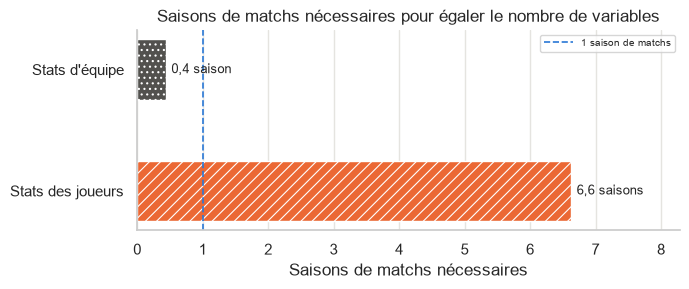

In [23]:
# E. Saisons de matchs nécessaires pour égaler le nombre de variables
saisons_nec = pd.Series({"Stats d'équipe": P_EQ / N_REF, "Stats des joueurs": P_JR / N_REF})
fig, ax = plt.subplots(figsize=(7, 2.6))
b = ax.barh(saisons_nec.index, saisons_nec.values, color=[GRIS, ORANGE], edgecolor="white",
            hatch=["...", "///"], height=0.5)
ax.bar_label(b, labels=[f"{virgule(s)} saison" + ("s" if s >= 2 else "") for s in saisons_nec],
             padding=4)
ax.axvline(1, color=BLEU, ls="--", lw=1.2, marker="", label="1 saison de matchs")
ax.invert_yaxis()
ax.set(xlabel="Saisons de matchs nécessaires", xlim=(0, saisons_nec.max() * 1.25),
       title="Saisons de matchs nécessaires pour égaler le nombre de variables")
ax.grid(axis="y", visible=False)
ax.legend(fontsize=7, loc="upper right")
sauver(fig, "defis_simple_E_saisons_necessaires")

pd.DataFrame(
    {
        "variables par match (p)": [P_EQ, P_JR],
        f"matchs dans la saison {SAISONS.max()} (n)": [N_REF, N_REF],
        "p / n": [P_EQ / N_REF, P_JR / N_REF],
    },
    index=saisons_nec.index,
).style.format("{:,.0f}").format("{:.1f}", subset=["p / n"])

### 4.4 Observations disponibles selon la profondeur de l'historique

Le seul moyen d'augmenter *n* est d'allonger l'historique d'entraînement : chaque saison
ajoute environ 1 300 matchs. Les lignes horizontales donnent le nombre de variables (*p*) de
quelques représentations ; tant que la courbe est sous une ligne, il y a moins de matchs que
de variables.

,variables (p),saisons pour n > p,saisons pour n > 10 p
"Équipe, situation « all » (MoneyPuck)",202,1,2
"Équipe, 5 situations (MoneyPuck)",1010,1,9
"Équipe, 21 rapports (NHL)",574,1,5
Équipe NHL × 3 fenêtres,1722,2,15
Joueurs NHL (patineurs + gardien),8696,8,<NA>
Joueurs NHL × 3 fenêtres,26088,<NA>,<NA>


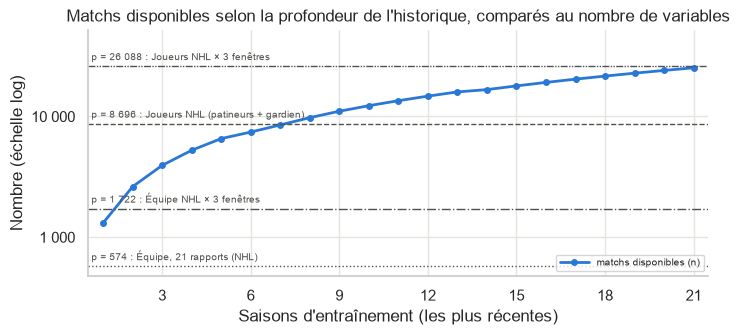

In [24]:
# matchs disponibles pour un entraînement sur les k dernières saisons terminées
n_cumul = n_saison.sort_index(ascending=False).cumsum().reset_index(drop=True)
n_cumul.index += 1
NIVEAUX_P = {  # représentation -> trait de la ligne horizontale
    "Équipe, 21 rapports\n(NHL)": ":",
    "Équipe NHL\n× 3 fenêtres": "-.",
    "Joueurs NHL\n(patineurs + gardien)": "--",
    "Joueurs NHL\n× 3 fenêtres": (0, (5, 1, 1, 1, 1, 1)),
}

fig, ax = plt.subplots()
ax.plot(n_cumul.index, n_cumul.values, color=BLEU, ls="-", marker="o", lw=2,
        label="matchs disponibles (n)")
for nom, ls in NIVEAUX_P.items():
    p = representations[nom]
    ax.axhline(p, color=GRIS, ls=ls, lw=1, marker="")
    ax.text(0.6, p * 1.08, f"p = {milliers(p)} : {nom.replace(chr(10), ' ')}", fontsize=7,
            color=GRIS, va="bottom")
ax.set_yscale("log")
ax.set_xlim(0.5, len(n_cumul) + 0.5)
ax.set_ylim(top=representations.max() * 2)
ax.set(
    xlabel="Saisons d'entraînement (les plus récentes)",
    ylabel="Nombre (échelle log)",
    title="Matchs disponibles selon la profondeur de l'historique, comparés au nombre de variables",
)
ax.yaxis.set_major_formatter(lambda v, _: milliers(v))
axe_saisons(ax)
ax.legend(fontsize=7, loc="lower right")
sauver(fig, "defis_historique_vs_variables")

# première profondeur où n dépasse p, puis 10 p
pd.DataFrame(
    {
        "variables (p)": representations,
        "saisons pour n > p": [
            n_cumul.index[n_cumul > p].min() if (n_cumul > p).any() else pd.NA
            for p in representations
        ],
        "saisons pour n > 10 p": [
            n_cumul.index[n_cumul > 10 * p].min() if (n_cumul > 10 * p).any() else pd.NA
            for p in representations
        ],
    },
).rename(index=lambda s: s.replace("\n", " ")).astype("Int64")

### 4.5 Observations disponibles au fil d'une saison

Un modèle réentraîné en cours de saison, ou qui ne s'appuie que sur la saison en cours, voit
*n* croître match après match, alors que *p* est fixé dès le départ. Matchs joués dans la
ligue, semaine après semaine, pour la dernière saison complète.

,semaine où n dépasse p (saison en cours seulement)
"Équipe, 21 rapports (NHL)",12
Équipe NHL × 3 fenêtres,<NA>
Joueurs NHL (patineurs + gardien),<NA>
Joueurs NHL × 3 fenêtres,<NA>


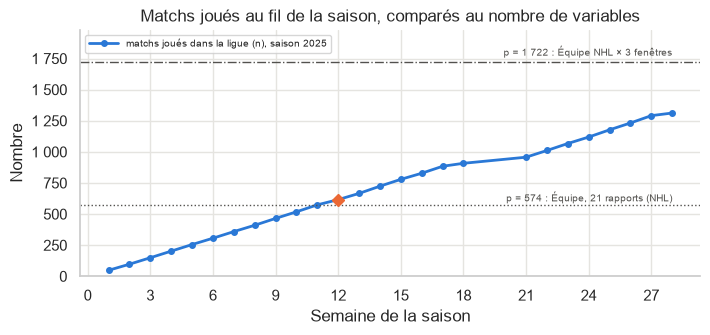

In [25]:
derniere = games[games["saison"] == SAISONS.max()].sort_values("date")
semaines = (derniere["date"] - derniere["date"].min()).dt.days // 7 + 1
n_semaine = derniere.groupby(semaines).size().cumsum()

fig, ax = plt.subplots()
ax.plot(n_semaine.index, n_semaine.values, color=BLEU, ls="-", marker="o", lw=2,
        label=f"matchs joués dans la ligue (n), saison {SAISONS.max()}")
for nom, ls in list(NIVEAUX_P.items())[:2]:
    p = representations[nom]
    ax.axhline(p, color=GRIS, ls=ls, lw=1, marker="")
    ax.text(n_semaine.index.max(), p * 1.02, f"p = {milliers(p)} : {nom.replace(chr(10), ' ')}",
            fontsize=7, color=GRIS, ha="right", va="bottom")
    croise = n_semaine.index[n_semaine > p].min()
    if pd.notna(croise):
        ax.plot(croise, n_semaine[croise], color=ORANGE, marker="D", ls="", ms=6)
ax.set_ylim(0, max(n_semaine.max(), representations[list(NIVEAUX_P)[1]]) * 1.15)
ax.set(
    xlabel="Semaine de la saison",
    ylabel="Nombre",
    title="Matchs joués au fil de la saison, comparés au nombre de variables",
)
ax.yaxis.set_major_formatter(lambda v, _: milliers(v))
axe_saisons(ax)
ax.legend(fontsize=7, loc="upper left")
sauver(fig, "defis_saison_vs_variables")

pd.Series(
    {nom.replace("\n", " "): n_semaine.index[n_semaine > representations[nom]].min()
     for nom in NIVEAUX_P},
    name="semaine où n dépasse p (saison en cours seulement)",
).astype("Int64").to_frame()

### 4.6 Matchs par joueur comparés aux variables par joueur

Au niveau individuel, le déséquilibre est encore plus marqué : un joueur dispute au plus 82
matchs dans une saison (souvent beaucoup moins), alors que chaque match le décrit par des
centaines de variables. Nombre de variables par joueur (rapports NHL) et nombre de matchs
joués par joueur-saison (maximum et médiane, 2005-2025).

,variables par joueur (p),"matchs joués, maximum","matchs joués, médiane",joueurs-saisons,part avec matchs < p
patineurs,237,85,55,18853,100.0%
gardiens,82,78,25,1968,100.0%


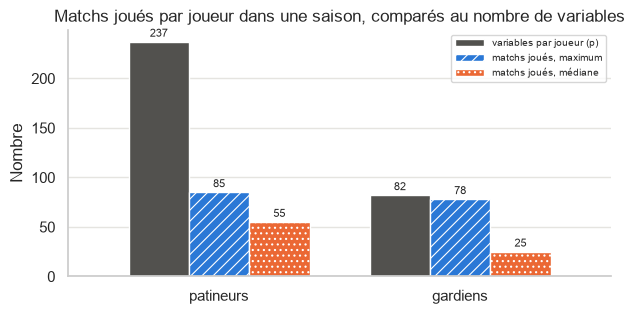

In [26]:
mj_sk = nhl_sk.groupby(["saison", "playerId"])["gameId"].nunique()
mj_gk = nhl_gk.groupby(["saison", "playerId"])["gameId"].nunique()
tab_joueurs = pd.DataFrame(
    {
        "variables par joueur (p)": [n_vars[("NHL", "patineurs")], n_vars[("NHL", "gardiens")]],
        "matchs joués, maximum": [mj_sk.max(), mj_gk.max()],
        "matchs joués, médiane": [mj_sk.median(), mj_gk.median()],
    },
    index=["patineurs", "gardiens"],
).astype(int)

fig, ax = plt.subplots(figsize=(7, 3.2))
tab_joueurs.plot.bar(ax=ax, width=0.75, color=[GRIS, BLEU, ORANGE], edgecolor="white", rot=0)
hachurer(ax)
for conteneur in ax.containers:
    ax.bar_label(conteneur, fontsize=8, padding=2)
ax.set(
    xlabel="",
    ylabel="Nombre",
    title="Matchs joués par joueur dans une saison, comparés au nombre de variables",
)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=7)
sauver(fig, "defis_matchs_par_joueur")

tab_joueurs.assign(
    **{
        "joueurs-saisons": [len(mj_sk), len(mj_gk)],
        "part avec matchs < p": [pct((mj_sk < n_vars[("NHL", "patineurs")]).mean()),
                                 pct((mj_gk < n_vars[("NHL", "gardiens")]).mean())],
    }
)

### 4.7 Variables et matchs par saison

Au fil des saisons, le nombre de matchs reste à peu près constant (borné par le calendrier),
alors que le nombre de variables disponibles augmente avec l'ajout de nouveaux rapports NHL
(2009) et des données de MoneyPuck (2008). Variables d'équipe par match (deux équipes) dont la
source couvre au moins 95 % des matchs de la saison (section 1.1).

saison,2005,2008,2009,2012,2020,2025
NHL,484,484,574,574,574,574
NHL + MoneyPuck,484,1494,1584,1584,1584,1584
matchs,1230,1230,1230,720,868,1312


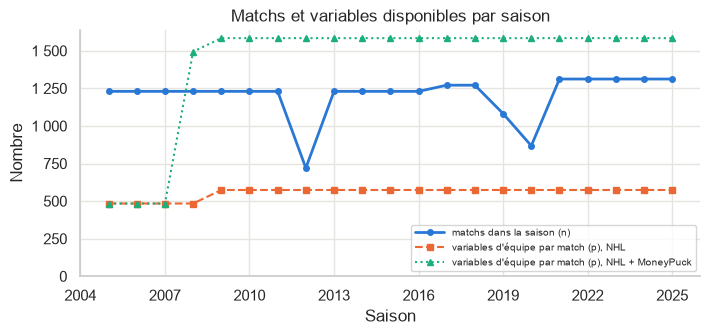

In [27]:
cols_table = colonnes.groupby("t")["c"].agg(set)
tables_eq = [stats_table("team", r) for r in REPORTS["team"]]
var_saison = pd.DataFrame(index=n_saison.index)
var_saison["NHL"] = [
    2 * len(set().union(*(cols_table.get(t, set()) for t in tables_eq
                          if couverture.loc[f"NHL · {t}"].get(s, 0) >= 0.95)))
    for s in var_saison.index
]
mp_ok = couverture.loc["MoneyPuck · équipes"].reindex(var_saison.index).fillna(0) >= 0.95
var_saison["NHL + MoneyPuck"] = var_saison["NHL"] + mp_ok * 2 * n_vars[("MoneyPuck", "équipes")]

fig, ax = plt.subplots()
ax.plot(n_saison.index, n_saison.values, color=BLEU, ls="-", marker="o", lw=2,
        label="matchs dans la saison (n)")
ax.plot(var_saison.index, var_saison["NHL"], color=ORANGE, ls="--", marker="s",
        label="variables d'équipe par match (p), NHL")
ax.plot(var_saison.index, var_saison["NHL + MoneyPuck"], color=AQUA, ls=":", marker="^",
        label="variables d'équipe par match (p), NHL + MoneyPuck")
ax.set_ylim(0)
ax.set(xlabel="Saison", ylabel="Nombre", title="Matchs et variables disponibles par saison")
ax.yaxis.set_major_formatter(lambda v, _: milliers(v))
axe_saisons(ax)
ax.legend(fontsize=7, loc="lower right")
sauver(fig, "defis_variables_par_saison")

var_saison.assign(matchs=n_saison).loc[[2005, 2008, 2009, 2012, 2020, SAISONS.max()]].T